# Experiment 06 – Developer Automation System using MCP
Run cells top to bottom. Cells 2–5 write the project files; the rest run the experiment. Colab's event loop is already running, so we `await` directly.

## 1. Install (pin `mcp<2` – the lab uses the `FastMCP` API)

In [ ]:
!pip -q install "mcp<2" pytest streamlit pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.6/234.6 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 58.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.8/80.8 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 43.4 MB/s eta 0:00:00


## 2. Write project files

In [ ]:
%%writefile mcp_server.py
"""MCP server exposing developer automation tools (FastMCP, stdio transport)."""
import ast
import asyncio
import json
import os
import re
import sys
from pathlib import Path

from mcp.server.fastmcp import FastMCP

PROJECT_DIR = Path(os.environ.get("PROJECT_DIR", "sample_developer_project")).resolve()
SKIP_DIRS = {"__pycache__", ".pytest_cache", ".git", ".venv", "node_modules"}

mcp = FastMCP("Developer Automation Server")


# ---------------------------------------------------------------- helpers
def safe_project_path(rel: str) -> Path:
    """Resolve a path and make sure it stays inside the project directory."""
    target = (PROJECT_DIR / rel).resolve()
    if target != PROJECT_DIR and PROJECT_DIR not in target.parents:
        raise PermissionError("Path outside project")
    return target


def _ok(**data) -> str:
    return json.dumps({"status": "ok", **data})


def _err(error_type: str, message: str) -> str:
    return json.dumps({"status": "error", "error_type": error_type, "error": message})


def _handle(e: Exception) -> str:
    if isinstance(e, PermissionError):
        return _err("security_error", str(e))
    if isinstance(e, (FileNotFoundError, IsADirectoryError, NotADirectoryError,
                      ValueError, SyntaxError, re.error)):
        return _err("input_error", f"{type(e).__name__}: {e}")
    return _err("execution_error", f"{type(e).__name__}: {e}")


def _py_files(base: Path):
    for p in sorted(base.rglob("*.py")):
        if not any(part in SKIP_DIRS for part in p.parts):
            yield p


# ------------------------------------------------------------------ tools
@mcp.tool()
def list_files(directory: str = ".") -> str:
    """List project files (LOW risk)."""
    try:
        base = safe_project_path(directory)
        if not base.is_dir():
            raise NotADirectoryError(directory)
        files = [
            {"path": str(p.relative_to(PROJECT_DIR)), "size_bytes": p.stat().st_size}
            for p in sorted(base.rglob("*"))
            if p.is_file() and not any(part in SKIP_DIRS for part in p.parts)
        ]
        return _ok(files=files, count=len(files))
    except Exception as e:
        return _handle(e)


@mcp.tool()
def read_file(file_path: str, max_chars: int = 20000) -> str:
    """Read a project file (LOW risk)."""
    try:
        p = safe_project_path(file_path)
        text = p.read_text(encoding="utf-8")
        return _ok(file=file_path, content=text[:max_chars], truncated=len(text) > max_chars,
                   lines=text.count("\n") + 1)
    except Exception as e:
        return _handle(e)


@mcp.tool()
def search_code(pattern: str, file_path: str = "") -> str:
    """Regex search over Python source (LOW risk). Empty file_path = all .py files."""
    try:
        rx = re.compile(pattern)
        targets = [safe_project_path(file_path)] if file_path else list(_py_files(PROJECT_DIR))
        matches = []
        for p in targets:
            for no, line in enumerate(p.read_text(encoding="utf-8").splitlines(), 1):
                if rx.search(line):
                    matches.append({"file": str(p.relative_to(PROJECT_DIR)), "line": no,
                                    "text": line.strip()})
        return _ok(pattern=pattern, matches=matches, count=len(matches))
    except Exception as e:
        return _handle(e)


@mcp.tool()
def analyze_python(file_path: str) -> str:
    """AST-based analysis of a Python file (LOW risk)."""
    try:
        p = safe_project_path(file_path)
        source = p.read_text(encoding="utf-8")
        tree = ast.parse(source)
        functions, classes, imports = [], [], []
        for node in ast.walk(tree):
            if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
                functions.append({"name": node.name, "line": node.lineno,
                                  "args": [a.arg for a in node.args.args],
                                  "has_docstring": ast.get_docstring(node) is not None})
            elif isinstance(node, ast.ClassDef):
                classes.append({"name": node.name, "line": node.lineno})
            elif isinstance(node, ast.Import):
                imports += [a.name for a in node.names]
            elif isinstance(node, ast.ImportFrom):
                imports.append(node.module or "")
        functions.sort(key=lambda f: f["line"])
        return _ok(file=file_path, functions=functions, classes=classes, imports=imports,
                   function_count=len(functions), class_count=len(classes),
                   lines=source.count("\n") + 1)
    except Exception as e:
        return _handle(e)


@mcp.tool()
async def run_tests(test_path: str = "", timeout: int = 60) -> str:
    """Run pytest in a separate process (MEDIUM risk)."""
    proc = None
    try:
        target = str(safe_project_path(test_path)) if test_path else str(PROJECT_DIR)
        proc = await asyncio.create_subprocess_exec(
            sys.executable, "-m", "pytest", "-q", "--no-header", "-p", "no:cacheprovider", target,
            cwd=str(PROJECT_DIR),
            stdout=asyncio.subprocess.PIPE, stderr=asyncio.subprocess.STDOUT)
        out, _ = await asyncio.wait_for(proc.communicate(), timeout=timeout)
        text = out.decode("utf-8", "replace")
        passed = re.search(r"(\d+) passed", text)
        failed = re.search(r"(\d+) failed", text)
        return _ok(returncode=proc.returncode,
                   passed=int(passed.group(1)) if passed else 0,
                   failed=int(failed.group(1)) if failed else 0,
                   output=text[-2000:])
    except asyncio.TimeoutError:
        if proc and proc.returncode is None:
            proc.kill()
        return _err("timeout", f"pytest exceeded {timeout}s")
    except Exception as e:
        return _handle(e)


if __name__ == "__main__":
    mcp.run(transport="stdio")

Writing mcp_server.py


In [ ]:
%%writefile sample_project.py
"""Creates the sample developer project used in the experiment."""
from pathlib import Path

FILES = {
    "calculator.py": '''"""Simple calculator functions."""


def add(a, b):
    """Return a + b."""
    return a + b


def subtract(a, b):
    """Return a - b."""
    return a - b


def multiply(a, b):
    """Return a * b."""
    return a * b


def divide(a, b):
    """Return a / b; raises ValueError on division by zero."""
    if b == 0:
        raise ValueError("Cannot divide by zero")
    return a / b


def calculate_square(n):
    """Return n squared."""
    return n * n
''',
    "app.py": '''from calculator import add, subtract, multiply, divide, calculate_square


def main():
    print("add(2, 3)      =", add(2, 3))
    print("subtract(5, 2) =", subtract(5, 2))
    print("multiply(4, 3) =", multiply(4, 3))
    print("divide(10, 2)  =", divide(10, 2))
    print("square(6)      =", calculate_square(6))


if __name__ == "__main__":
    main()
''',
    "test_calculator.py": '''import pytest
from calculator import add, subtract, multiply, divide, calculate_square


def test_add():
    assert add(2, 3) == 5


def test_subtract():
    assert subtract(5, 2) == 3


def test_multiply():
    assert multiply(4, 3) == 12


def test_divide():
    assert divide(10, 2) == 5


def test_divide_by_zero():
    with pytest.raises(ValueError):
        divide(1, 0)


def test_square():
    assert calculate_square(6) == 36
''',
    "README.md": "# Sample Developer Project\n\nA tiny calculator project used to demo the MCP Developer Automation System.\n",
}


def create_sample_project(path="sample_developer_project") -> Path:
    root = Path(path)
    root.mkdir(parents=True, exist_ok=True)
    for name, content in FILES.items():
        (root / name).write_text(content, encoding="utf-8")
    return root


if __name__ == "__main__":
    print("Created", create_sample_project().resolve())

Writing sample_project.py


In [ ]:
%%writefile dev_automation.py
"""MCP client + planner, supervisor, policy, validator, recovery, tracing, benchmark."""
import asyncio
import json
import logging
import os
import re
import statistics
import sys
import time
import uuid
from contextlib import asynccontextmanager
from datetime import datetime
from pathlib import Path

from mcp import ClientSession
from mcp.client.stdio import StdioServerParameters, stdio_client

BASE = Path(__file__).resolve().parent
SERVER_PATH = BASE / "mcp_server.py"
LOG_DIR = Path("mcp_logs")
LOG_DIR.mkdir(exist_ok=True)
TRACE_FILE = LOG_DIR / "mcp_traces.jsonl"
REPORT_FILE = LOG_DIR / "developer_automation_report.json"

logging.basicConfig(filename=LOG_DIR / "execution.log", level=logging.INFO,
                    format="%(asctime)s %(levelname)s %(message)s")
log = logging.getLogger("dev_automation")

# ---- policy / classification tables (Tables 3 and 4) ----
TOOL_RISK = {"list_files": "LOW", "read_file": "LOW", "search_code": "LOW",
             "analyze_python": "LOW", "run_tests": "MEDIUM"}
ALLOWED_RISK = {"LOW", "MEDIUM"}
RETRYABLE = {"timeout", "execution_error"}
MAX_RETRIES = 2
CALL_TIMEOUT = 90
EXPECTED_KEYS = {"list_files": ["files"], "read_file": ["content"], "search_code": ["matches"],
                 "analyze_python": ["functions", "classes"], "run_tests": ["returncode"]}


# ============================================================ connection
@asynccontextmanager
async def mcp_session(project_dir):
    """Start the MCP server over stdio and yield an initialized ClientSession."""
    params = StdioServerParameters(
        command=sys.executable, args=[str(SERVER_PATH)],
        env={**os.environ, "PROJECT_DIR": str(Path(project_dir).resolve())})
    # errlog goes to a file: notebooks' sys.stderr has no fileno() and would crash
    with open(LOG_DIR / "server_stderr.log", "a") as errlog:
        async with stdio_client(params, errlog=errlog) as (read, write):
            async with ClientSession(read, write) as session:
                await session.initialize()
                yield session


async def discover_tools(session):
    tools = await session.list_tools()
    return {t.name: t.inputSchema for t in tools.tools}


# ================================================================ agents
def plan_request(request: str):
    """Planner: natural language -> structured tasks."""
    text = request.lower()
    m = re.search(r"[\w./\\-]+\.py\b", request)
    file = m.group(0) if m else None
    tasks = []

    def add(tool, args, deps=None):
        tid = f"TASK-{len(tasks) + 1:03d}"
        tasks.append({"task_id": tid, "tool": tool, "args": args, "depends_on": deps or []})
        return tid

    if re.search(r"\blist\b.*\bfiles?\b|\bfiles?\b.*\blist\b|project files", text):
        add("list_files", {"directory": "."})
    if file and re.search(r"\b(read|open|display|view|show)\b", text) and "analy" not in text:
        add("read_file", {"file_path": file})
    analyze_id = None
    if re.search(r"analy[sz]e|inspect|\bast\b", text):
        analyze_id = add("analyze_python", {"file_path": file or ""})
    if re.search(r"\b(search|find|grep)\b", text):
        if re.search(r"function|\bdef\b", text):
            pattern = r"^\s*def\s+\w+"
        elif "class" in text:
            pattern = r"^\s*class\s+\w+"
        elif "import" in text:
            pattern = r"^\s*(import|from)\s+\w+"
        else:
            q = re.search(r"[\"']([^\"']+)[\"']", request)
            pattern = q.group(1) if q else ""
        add("search_code", {"pattern": pattern, "file_path": file or ""})
    if re.search(r"\btests?\b|pytest", text):
        tp = file if file and Path(file).name.startswith("test_") else ""
        add("run_tests", {"test_path": tp}, [analyze_id] if analyze_id else [])
    return tasks


def supervise(tasks, available):
    """Supervisor: tool must exist and required arguments must be present."""
    approved, rejected = [], []
    for t in tasks:
        schema = available.get(t["tool"])
        if schema is None:
            rejected.append({**t, "reason": f"tool '{t['tool']}' not exposed by server"})
            continue
        missing = [r for r in schema.get("required", [])
                   if not isinstance(t["args"].get(r), str) or not t["args"].get(r).strip()]
        if missing:
            rejected.append({**t, "reason": f"missing/empty argument(s): {missing}"})
        else:
            approved.append(t)
    return approved, rejected


def policy_check(tasks):
    """Safety layer: allow/block by risk level."""
    allowed, blocked = [], []
    for t in tasks:
        risk = TOOL_RISK.get(t["tool"], "HIGH")
        t = {**t, "risk": risk}
        (allowed if risk in ALLOWED_RISK else blocked).append(t)
    return allowed, blocked


def validate(tool, payload):
    """Validator: status + structure of the result."""
    if payload.get("status") != "ok":
        return False, f"status={payload.get('status')} ({payload.get('error_type')})"
    missing = [k for k in EXPECTED_KEYS.get(tool, []) if k not in payload]
    if missing:
        return False, f"missing keys {missing}"
    return True, "ok"


# ===================================================== execution + tracing
def write_trace(rec):
    with open(TRACE_FILE, "a", encoding="utf-8") as f:
        f.write(json.dumps(rec) + "\n")


def read_traces(limit=200):
    if not TRACE_FILE.exists():
        return []
    lines = TRACE_FILE.read_text(encoding="utf-8").strip().splitlines()[-limit:]
    return [json.loads(x) for x in lines]


async def execute_task(session, task, trace_id, max_retries=MAX_RETRIES):
    """Call one MCP tool with failure classification, limited retry and tracing."""
    attempt = 0
    while True:
        attempt += 1
        t0 = time.perf_counter()
        try:
            res = await asyncio.wait_for(
                session.call_tool(task["tool"], arguments=task["args"]), CALL_TIMEOUT)
            text = "".join(getattr(c, "text", "") for c in res.content)
            if res.isError:
                payload = {"status": "error", "error_type": "tool_error", "error": text[:300]}
            else:
                try:
                    payload = json.loads(text)
                except json.JSONDecodeError:
                    payload = {"status": "error", "error_type": "execution_error",
                               "error": "non-JSON tool output"}
        except asyncio.TimeoutError:
            payload = {"status": "error", "error_type": "timeout", "error": "client timeout"}
        except Exception as e:  # noqa: BLE001
            payload = {"status": "error", "error_type": "execution_error", "error": str(e)}
        ms = round((time.perf_counter() - t0) * 1000, 2)
        ok = payload.get("status") == "ok"
        write_trace({"trace_id": trace_id, "task_id": task["task_id"], "tool": task["tool"],
                     "arguments": task["args"], "status": "success" if ok else "failure",
                     "attempt": attempt, "execution_ms": ms,
                     "timestamp": datetime.now().isoformat(timespec="seconds"),
                     "error": None if ok else payload.get("error")})
        log.info("%s %s %s attempt=%d %.2fms ok=%s", trace_id, task["task_id"], task["tool"],
                 attempt, ms, ok)
        err_type = payload.get("error_type")
        if not ok and err_type in RETRYABLE and attempt <= max_retries:
            log.warning("%s retrying (%s)", task["task_id"], err_type)
            await asyncio.sleep(0.2 * attempt)
            continue
        valid, vmsg = validate(task["tool"], payload)
        return {"task_id": task["task_id"], "tool": task["tool"], "args": task["args"],
                "risk": task.get("risk", TOOL_RISK.get(task["tool"])),
                "status": "success" if ok else "failure", "error_type": err_type,
                "error": payload.get("error"), "attempts": attempt, "ms": ms,
                "valid": valid, "validation": vmsg, "payload": payload}


async def run_workflow(request, project_dir="sample_developer_project", mode="parallel"):
    """Full pipeline: plan -> supervise -> policy -> execute (phases) -> validate -> report."""
    trace_id = "TRACE-" + uuid.uuid4().hex[:8].upper()
    t_start = time.perf_counter()
    async with mcp_session(project_dir) as session:
        available = await discover_tools(session)
        plan = plan_request(request)
        approved, rejected = supervise(plan, available)
        approved, blocked = policy_check(approved)
        for r in rejected + blocked:
            write_trace({"trace_id": trace_id, "task_id": r["task_id"], "tool": r["tool"],
                         "arguments": r["args"], "status": "rejected",
                         "timestamp": datetime.now().isoformat(timespec="seconds"),
                         "error": r.get("reason", "blocked by policy")})

        independent = [t for t in approved if not t["depends_on"]]
        dependent = [t for t in approved if t["depends_on"]]
        results = {}

        # Phase 1: independent tasks (parallel or sequential)
        p1 = time.perf_counter()
        if mode == "parallel":
            out = await asyncio.gather(*[execute_task(session, t, trace_id) for t in independent])
        else:
            out = [await execute_task(session, t, trace_id) for t in independent]
        for r in out:
            results[r["task_id"]] = r
        p1_ms = round((time.perf_counter() - p1) * 1000, 2)

        # Phase 2: dependency validation, Phase 3: dependent tasks (sequential)
        p3 = time.perf_counter()
        for t in dependent:
            bad = [d for d in t["depends_on"] if not (d in results and results[d]["valid"])]
            if bad:
                results[t["task_id"]] = {
                    "task_id": t["task_id"], "tool": t["tool"], "args": t["args"],
                    "risk": t.get("risk"), "status": "skipped", "valid": False,
                    "validation": f"dependency {bad} failed validation", "ms": 0, "attempts": 0,
                    "payload": {}}
                continue
            results[t["task_id"]] = await execute_task(session, t, trace_id)
        p3_ms = round((time.perf_counter() - p3) * 1000, 2)

    ordered = [results[t["task_id"]] for t in approved if t["task_id"] in results]
    report = {
        "trace_id": trace_id, "request": request, "mode": mode,
        "timestamp": datetime.now().isoformat(timespec="seconds"),
        "tools_discovered": list(available), "plan": plan,
        "rejected": rejected, "blocked_by_policy": blocked, "results": ordered,
        "summary": {
            "tasks_planned": len(plan), "succeeded": sum(r["status"] == "success" for r in ordered),
            "failed": sum(r["status"] == "failure" for r in ordered),
            "skipped": sum(r["status"] == "skipped" for r in ordered),
            "rejected": len(rejected), "blocked": len(blocked),
            "phase1_ms": p1_ms, "phase3_ms": p3_ms,
            "total_ms": round((time.perf_counter() - t_start) * 1000, 2),
            "dop": len(independent) if mode == "parallel" else 1,
        },
    }
    REPORT_FILE.write_text(json.dumps(report, indent=2), encoding="utf-8")
    return report


# ============================================================ extras
async def security_demo(project_dir="sample_developer_project"):
    """Path traversal + missing file: both must be stopped without retry."""
    trace_id = "TRACE-" + uuid.uuid4().hex[:8].upper()
    cases = [("read_file", {"file_path": "../../etc/passwd"}),
             ("read_file", {"file_path": "does_not_exist.py"}),
             ("run_tests", {"test_path": "../outside"})]
    out = []
    async with mcp_session(project_dir) as session:
        for i, (tool, args) in enumerate(cases, 1):
            out.append(await execute_task(session, {"task_id": f"TASK-{i:03d}", "tool": tool,
                                                    "args": args}, trace_id))
    return out


async def run_benchmark(project_dir="sample_developer_project", runs=5):
    """Variation 9: 4 independent tool calls, sequential vs parallel, repeated `runs` times."""
    calls = [("analyze_python", {"file_path": "calculator.py"}),
             ("search_code", {"pattern": r"^\s*def\s+\w+", "file_path": "calculator.py"}),
             ("list_files", {"directory": "."}),
             ("read_file", {"file_path": "calculator.py"})]
    rows = []
    async with mcp_session(project_dir) as session:
        await session.call_tool("list_files", arguments={"directory": "."})  # warm-up
        for i in range(1, runs + 1):
            t0 = time.perf_counter()
            for tool, args in calls:
                await session.call_tool(tool, arguments=args)
            seq = (time.perf_counter() - t0) * 1000
            t0 = time.perf_counter()
            await asyncio.gather(*[session.call_tool(t, arguments=a) for t, a in calls])
            par = (time.perf_counter() - t0) * 1000
            rows.append({"run": i, "sequential_ms": round(seq, 2), "parallel_ms": round(par, 2)})
    avg_s = statistics.mean(r["sequential_ms"] for r in rows)
    avg_p = statistics.mean(r["parallel_ms"] for r in rows)
    summary = {"tasks": len(calls), "runs": runs, "avg_sequential_ms": round(avg_s, 2),
               "avg_parallel_ms": round(avg_p, 2),
               "avg_time_per_tool_ms": round(avg_s / len(calls), 2),
               "time_reduction_pct": round((avg_s - avg_p) / avg_s * 100, 2)}
    (LOG_DIR / "performance_comparison.json").write_text(
        json.dumps({"rows": rows, "summary": summary}, indent=2))
    return rows, summary

Writing dev_automation.py


In [ ]:
%%writefile streamlit_app.py
import asyncio
import json
from pathlib import Path

import pandas as pd
import streamlit as st

from dev_automation import (REPORT_FILE, discover_tools, mcp_session, read_traces,
                            run_benchmark, run_workflow, security_demo, TOOL_RISK)
from sample_project import create_sample_project

st.set_page_config(page_title="MCP Developer Automation", page_icon="🛠️", layout="wide")
st.title("🛠️ Developer Automation System using MCP")
st.caption("Planner → Supervisor → Policy → MCP Client → MCP Server (5 tools) → Validator → Trace → Report")

with st.sidebar:
    st.header("Settings")
    project_dir = st.text_input("Project directory", "sample_developer_project")
    mode = st.radio("Phase-1 execution", ["parallel", "sequential"])
    if st.button("Create / reset sample project"):
        create_sample_project(project_dir)
        st.success(f"Sample project ready in {project_dir}/")
    st.markdown("**Tool risk levels**")
    st.table(pd.DataFrame(TOOL_RISK.items(), columns=["tool", "risk"]))

if not Path(project_dir).exists():
    create_sample_project(project_dir)

tab_run, tab_tools, tab_bench, tab_sec, tab_trace = st.tabs(
    ["▶ Run request", "🔍 Tool discovery", "⏱ Performance", "🛡 Security & failures", "📜 Traces"])

# ---------------------------------------------------------------- run
with tab_run:
    examples = ["Analyze calculator.py and run its tests",
                "Analyze calculator.py and search for all function definitions",
                "List project files",
                "Read calculator.py",
                "Search for \"divide\" in calculator.py"]
    pick = st.selectbox("Example requests", examples)
    request = st.text_input("Developer request", pick)
    if st.button("Run workflow", type="primary"):
        with st.spinner("Running through MCP..."):
            rep = asyncio.run(run_workflow(request, project_dir, mode))
        s = rep["summary"]
        c = st.columns(5)
        c[0].metric("Trace ID", rep["trace_id"])
        c[1].metric("Succeeded", s["succeeded"])
        c[2].metric("Failed / skipped", f"{s['failed']} / {s['skipped']}")
        c[3].metric("Total time", f"{s['total_ms']} ms")
        c[4].metric("DOP (phase 1)", s["dop"])
        st.subheader("Plan")
        st.dataframe(pd.DataFrame(rep["plan"]), width="stretch")
        if rep["rejected"] or rep["blocked_by_policy"]:
            st.warning("Supervisor/policy rejected: " +
                       json.dumps([r.get("reason", "blocked") for r in rep["rejected"] + rep["blocked_by_policy"]]))
        st.subheader("Execution results")
        st.dataframe(pd.DataFrame([{k: v for k, v in r.items() if k != "payload"}
                                   for r in rep["results"]]), width="stretch")
        for r in rep["results"]:
            with st.expander(f"{r['task_id']} · {r['tool']} · {r['status']}"):
                st.json(r["payload"])
        st.download_button("Download report JSON", json.dumps(rep, indent=2),
                           file_name="developer_automation_report.json")

# ---------------------------------------------------------------- tools
with tab_tools:
    if st.button("Discover tools (session.list_tools())"):
        async def _d():
            async with mcp_session(project_dir) as s:
                return await discover_tools(s)
        tools = asyncio.run(_d())
        st.success(f"{len(tools)} tools discovered over stdio")
        for name, schema in tools.items():
            with st.expander(f"{name}  [{TOOL_RISK.get(name)}]"):
                st.json(schema)

# ---------------------------------------------------------------- perf
with tab_bench:
    runs = st.slider("Runs", 3, 10, 5)
    if st.button("Run sequential vs parallel benchmark"):
        rows, summ = asyncio.run(run_benchmark(project_dir, runs))
        df = pd.DataFrame(rows).set_index("run")
        st.dataframe(df, width="stretch")
        st.bar_chart(df)
        st.json(summ)
        st.info("Tool calls take only a few ms, so scheduling/stdio overhead is comparable to the "
                "work itself; parallelism pays off more for long tools such as run_tests.")

# ---------------------------------------------------------------- security
with tab_sec:
    st.write("Path traversal, missing file and out-of-project test path must all be "
             "stopped **without retry**.")
    if st.button("Run security / failure demo"):
        out = asyncio.run(security_demo(project_dir))
        st.dataframe(pd.DataFrame([{k: v for k, v in r.items() if k != "payload"} for r in out]),
                     width="stretch")

# ---------------------------------------------------------------- traces
with tab_trace:
    traces = read_traces(500)
    if traces:
        st.dataframe(pd.DataFrame(traces).iloc[::-1], width="stretch")
    else:
        st.info("No traces yet – run a workflow first.")
    if REPORT_FILE.exists():
        st.download_button("Download latest report", REPORT_FILE.read_text(),
                           file_name="developer_automation_report.json", key="dl2")

Writing streamlit_app.py


## 3. Create sample project and discover tools

In [ ]:
from sample_project import create_sample_project
from dev_automation import *
import json, pandas as pd
print("Created:", create_sample_project().resolve())

async with mcp_session("sample_developer_project") as s:
    tools = await discover_tools(s)
for name, schema in tools.items():
    print(f"{name:15s} risk={TOOL_RISK[name]:6s} args={list(schema['properties'])}")

Created: /content/sample_developer_project
list_files      risk=LOW    args=['directory']
read_file       risk=LOW    args=['file_path', 'max_chars']
search_code     risk=LOW    args=['pattern', 'file_path']
analyze_python  risk=LOW    args=['file_path']
run_tests       risk=MEDIUM args=['test_path', 'timeout']


## 4. Hybrid workflow: analyze_python ‖ search_code → validate → run_tests

In [ ]:
rep = await run_workflow("Analyze calculator.py and run its tests", mode="parallel")
print(rep["trace_id"], rep["summary"])
pd.DataFrame([{k:v for k,v in r.items() if k!="payload"} for r in rep["results"]])

TRACE-1B363A9A {'tasks_planned': 2, 'succeeded': 2, 'failed': 0, 'skipped': 0, 'rejected': 0, 'blocked': 0, 'phase1_ms': 8.69, 'phase3_ms': 1699.4, 'total_ms': 4426.42, 'dop': 1}


,task_id,tool,args,risk,status,error_type,error,attempts,ms,valid,validation
0,TASK-001,analyze_python,{'file_path': 'calculator.py'},LOW,success,None,None,1,8.21,True,ok
1,TASK-002,run_tests,{'test_path': ''},MEDIUM,success,None,None,1,1699.21,True,ok


In [ ]:
rep = await run_workflow("Analyze calculator.py and search for all function definitions")
print(rep["trace_id"], rep["summary"])
print(json.dumps(rep["results"][0]["payload"]["functions"], indent=1)[:800])
pd.DataFrame(rep["plan"])

TRACE-6F038E4D {'tasks_planned': 2, 'succeeded': 2, 'failed': 0, 'skipped': 0, 'rejected': 0, 'blocked': 0, 'phase1_ms': 12.86, 'phase3_ms': 0.0, 'total_ms': 2861.29, 'dop': 2}
[
 {
  "name": "add",
  "line": 4,
  "args": [
   "a",
   "b"
  ],
  "has_docstring": true
 },
 {
  "name": "subtract",
  "line": 9,
  "args": [
   "a",
   "b"
  ],
  "has_docstring": true
 },
 {
  "name": "multiply",
  "line": 14,
  "args": [
   "a",
   "b"
  ],
  "has_docstring": true
 },
 {
  "name": "divide",
  "line": 19,
  "args": [
   "a",
   "b"
  ],
  "has_docstring": true
 },
 {
  "name": "calculate_square",
  "line": 26,
  "args": [
   "n"
  ],
  "has_docstring": true
 }
]


,task_id,tool,args,depends_on
0,TASK-001,analyze_python,{'file_path': 'calculator.py'},[]
1,TASK-002,search_code,"{'pattern': '^\s*def\s+\w+', 'file_path': 'cal...",[]


In [ ]:
for req in ["List project files", "Read calculator.py", 'Search for "divide" in calculator.py']:
    r = await run_workflow(req)
    print(req, "->", [(x["tool"], x["status"]) for x in r["results"]])

List project files -> [('list_files', 'success')]
Read calculator.py -> [('read_file', 'success')]
Search for "divide" in calculator.py -> [('search_code', 'success')]


## 5. Safety, failure classification and recovery (no retry for input/security errors)

In [ ]:
out = await security_demo()
pd.DataFrame([{k:v for k,v in r.items() if k!="payload"} for r in out])[["tool","args","status","error_type","attempts","error"]]

,tool,args,status,error_type,attempts,error
0,read_file,{'file_path': '../../etc/passwd'},failure,security_error,1,Path outside project
1,read_file,{'file_path': 'does_not_exist.py'},failure,input_error,1,FileNotFoundError: [Errno 2] No such file or d...
2,run_tests,{'test_path': '../outside'},failure,security_error,1,Path outside project


## 6. Variation 9 – performance comparison (sequential vs parallel, 4 tools × 5 runs)

,run,sequential_ms,parallel_ms
0,1,25.32,21.53
1,2,22.92,21.11
2,3,23.95,21.45
3,4,23.24,21.32
4,5,23.04,20.43


{'tasks': 4, 'runs': 5, 'avg_sequential_ms': 23.69, 'avg_parallel_ms': 21.17, 'avg_time_per_tool_ms': 5.92, 'time_reduction_pct': 10.66}


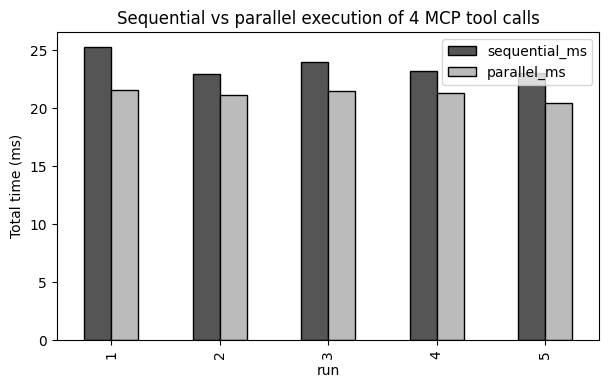

In [ ]:
import matplotlib.pyplot as plt
rows, summ = await run_benchmark(runs=5)
df = pd.DataFrame(rows); display(df); print(summ)
df.set_index("run").plot(kind="bar", figsize=(7,4), color=["#555","#bbb"], edgecolor="black")
plt.ylabel("Total time (ms)"); plt.title("Sequential vs parallel execution of 4 MCP tool calls"); plt.show()

## 7. Traces and generated artifacts

In [ ]:
print(open("mcp_logs/mcp_traces.jsonl").read()[-1500:])
!ls -la mcp_logs

", "task_id": "TASK-001", "tool": "list_files", "arguments": {"directory": "."}, "status": "success", "attempt": 1, "execution_ms": 10.01, "timestamp": "2026-10-22T06:55:42", "error": null}
{"trace_id": "TRACE-7B9B8FE4", "task_id": "TASK-001", "tool": "read_file", "arguments": {"file_path": "calculator.py"}, "status": "success", "attempt": 1, "execution_ms": 6.72, "timestamp": "2026-10-22T06:55:50", "error": null}
{"trace_id": "TRACE-072D54C8", "task_id": "TASK-001", "tool": "search_code", "arguments": {"pattern": "divide", "file_path": "calculator.py"}, "status": "success", "attempt": 1, "execution_ms": 6.81, "timestamp": "2026-10-22T06:55:52", "error": null}
{"trace_id": "TRACE-EE8C3518", "task_id": "TASK-001", "tool": "read_file", "arguments": {"file_path": "../../etc/passwd"}, "status": "failure", "attempt": 1, "execution_ms": 14.53, "timestamp": "2026-10-22T06:55:55", "error": "Path outside project"}
{"trace_id": "TRACE-EE8C3518", "task_id": "TASK-002", "tool": "read_file", "argum

## 8. Streamlit UI inside Colab (Cloudflare tunnel: no password, more reliable than localtunnel)
Run this cell, wait ~15 s, then open the `https://….trycloudflare.com` link it prints. If the page looks broken, hard-refresh with Ctrl+Shift+R.

In [ ]:
!pkill -f streamlit || true
!pkill -f cloudflared || true
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared && chmod +x cloudflared
!nohup streamlit run streamlit_app.py --server.port 8501 --server.headless true --server.enableCORS false --server.enableXsrfProtection false > /content/streamlit_log.txt 2>&1 &
!sleep 6
!nohup ./cloudflared tunnel --url http://localhost:8501 --no-autoupdate > /content/cloudflared_log.txt 2>&1 &
!sleep 10
!grep -o "https://[a-z0-9-]*\.trycloudflare\.com" /content/cloudflared_log.txt | head -1

^C
^C
https://podcasts-carlos-hist-remember.trycloudflare.com


If no link was printed, run `!tail -20 /content/cloudflared_log.txt` and `!tail -20 /content/streamlit_log.txt` to see why.